# Task 16 — Workforce Headcount and Exits Forecast

Phase 4 | CortexHR

This notebook audits the supplied data, explores trend and seasonality, builds a seasonal baseline and a SARIMAX candidate with workforce-event regressors, backtests the final six historical months, and forecasts six months ahead with central 80% prediction intervals.

All outputs are saved inside `phase-4/reports/`, `phase-4/evidence/` and `phase-4/models/`.

**Aggregation rule:** the company-wide `ALL` row is not added to departments. Company forecasts are calculated by summing department forecasts (including D00), preserving the historical company total.

## 1. Imports, paths and data loading

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import statsmodels

warnings.filterwarnings("ignore", category=ConvergenceWarning)
np.random.seed(42)

# Find phase-4 whether Jupyter starts in /workspace or a subfolder.
cwd = Path.cwd()
if cwd.name == "phase-4":
    PHASE_ROOT = cwd
elif (cwd / "phase-4").is_dir():
    PHASE_ROOT = cwd / "phase-4"
else:
    PHASE_ROOT = next((p for p in cwd.parents if p.name == "phase-4"), None)
    if PHASE_ROOT is None:
        raise FileNotFoundError(f"Cannot locate phase-4 from {cwd}")

DATA_DIR = PHASE_ROOT / "data" / "raw"
HISTORY_PATH = DATA_DIR / "monthly_headcount_history.csv"
EVENTS_PATH = DATA_DIR / "workforce_events.csv"
SAMPLE_PATH = DATA_DIR / "sample_forecast.csv"
REPORT_DIR = PHASE_ROOT / "reports"
EVIDENCE_DIR = PHASE_ROOT / "evidence"
MODEL_DIR = PHASE_ROOT / "models"
for folder in [REPORT_DIR, EVIDENCE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

history = pd.read_csv(DATA_DIR / "monthly_headcount_history.csv")
events = pd.read_csv(DATA_DIR / "workforce_events.csv")
sample_template = pd.read_csv(DATA_DIR / "sample_forecast.csv")

required_history = {
    "month", "department_id", "department_name", "headcount_end",
    "hires", "exits", "voluntary_exits", "transfers_in",
    "transfers_out", "headcount_start", "hiring_drive_flag",
    "attrition_rate_monthly_pct", "appraisal_cycle_flag",
    "financial_year_end_flag"
}
required_events = {"event_id", "start_date", "end_date", "department_id", "event_name", "description"}
required_sample = {
    "forecast_id", "metric", "department_id", "forecast_month",
    "forecast_value", "lower_80", "upper_80", "method",
    "trained_through", "model_version"
}
assert required_history.issubset(history.columns), required_history - set(history.columns)
assert required_events.issubset(events.columns), required_events - set(events.columns)
assert required_sample.issubset(sample_template.columns), required_sample - set(sample_template.columns)

history["month"] = pd.to_datetime(history["month"]).dt.to_period("M").dt.to_timestamp()
events["start_date"] = pd.to_datetime(events["start_date"]).dt.to_period("M").dt.to_timestamp()
events["end_date"] = pd.to_datetime(events["end_date"]).dt.to_period("M").dt.to_timestamp()
sample_template["forecast_month"] = pd.to_datetime(sample_template["forecast_month"]).dt.to_period("M").dt.to_timestamp()

numeric_cols = [
    "headcount_end", "hires", "exits", "voluntary_exits", "transfers_in",
    "transfers_out", "headcount_start", "hiring_drive_flag",
    "attrition_rate_monthly_pct", "appraisal_cycle_flag", "financial_year_end_flag"
]
history[numeric_cols] = history[numeric_cols].apply(pd.to_numeric, errors="raise")
history = history.sort_values(["department_id", "month"]).reset_index(drop=True)
events = events.sort_values(["start_date", "end_date"]).reset_index(drop=True)
sample_template = sample_template.sort_values(["metric", "department_id", "forecast_month"]).reset_index(drop=True)

assert not history.duplicated(["month", "department_id"]).any(), "Duplicate month/department rows found."
assert history[numeric_cols].notna().all().all(), "Missing values in numeric history."
assert events[["start_date", "end_date"]].notna().all().all(), "Missing event dates."

history_months = pd.date_range(history["month"].min(), history["month"].max(), freq="MS")
assert history["month"].nunique() == len(history_months), "Historical monthly series has gaps."
forecast_months = pd.DatetimeIndex(sorted(sample_template["forecast_month"].unique()))
assert len(forecast_months) == 6, "Sample forecast must specify six months."
assert forecast_months.min() > history["month"].max(), "Forecast months overlap history."

department_ids = sorted(history.loc[history.department_id != "ALL", "department_id"].unique())
department_names = (
    history.loc[history.department_id != "ALL", ["department_id", "department_name"]]
    .drop_duplicates().set_index("department_id")["department_name"].to_dict()
)
trained_through = history["month"].max()
print("Phase root:", PHASE_ROOT)
print("Statsmodels:", statsmodels.__version__)
print("History:", history.shape, history["month"].min().date(), "to", trained_through.date())
print("Events:", events.shape, "| sample:", sample_template.shape)
print("Forecast months:", [d.strftime("%Y-%m") for d in forecast_months])
print("Missing values:", history.isna().sum().sum(), events.isna().sum().sum(), sample_template.isna().sum().sum())
display(history.head())
display(events)
display(sample_template.head())

Phase root: /workspace/phase-4
Statsmodels: 0.15.0
History: (972, 14) 2020-01-01 to 2026-09-01
Events: (9, 6) | sample: (72, 10)
Forecast months: ['2026-10', '2026-11', '2026-12', '2027-01', '2027-02', '2027-03']
Missing values: 0 0 0


,month,department_id,department_name,headcount_end,hires,exits,voluntary_exits,transfers_in,transfers_out,headcount_start,hiring_drive_flag,attrition_rate_monthly_pct,appraisal_cycle_flag,financial_year_end_flag
0,2020-01-01,ALL,Company total,171,5,4,4,0,0,170,0,2.35,0,0
1,2020-02-01,ALL,Company total,167,1,5,5,0,0,171,0,2.92,0,0
2,2020-03-01,ALL,Company total,167,4,4,4,0,0,167,0,2.40,0,1
3,2020-04-01,ALL,Company total,165,0,2,2,0,0,167,0,1.20,1,0
4,2020-05-01,ALL,Company total,162,0,3,3,0,0,165,0,1.82,0,0


,event_id,start_date,end_date,department_id,event_name,description
0,EV-01,2020-04-01,2020-06-01,ALL,COVID-19 hiring freeze,Hiring almost stopped; exits slowed
1,EV-02,2021-04-01,2021-04-01,ALL,Reduced increment cycle,Average increments cut by about 25%
2,EV-03,2022-09-01,2022-11-01,D06,Support scale-up for festive season,Large batch of Support Associates hired
3,EV-04,2023-07-01,2023-07-01,ALL,Hybrid work policy introduced,Three-day office policy for most roles
4,EV-05,2023-07-01,2023-08-01,D01,Engineering hiring drive,Hiring doubled for two months
5,EV-06,2024-01-01,2024-02-01,D04,Sales expansion hiring drive,New regional sales teams
6,EV-07,2025-01-01,2025-06-01,D03,Data & AI team build-out,Data & AI hiring more than doubled
7,EV-08,2025-04-01,2025-04-01,ALL,New 5-point appraisal framework,Ratings now drive increments and bonus
8,EV-09,2026-04-01,2026-04-01,ALL,Performance bonus paid with April payroll,Bonus paid as % of annual fixed pay


,forecast_id,metric,department_id,forecast_month,forecast_value,lower_80,upper_80,method,trained_through,model_version
0,FC-0067,attrition_rate_monthly_pct,ALL,2026-10-01,1.02,0.27,1.77,same-month average of last 3 years,2026-09,trend-seasonal-baseline-0.1
1,FC-0068,attrition_rate_monthly_pct,ALL,2026-11-01,1.01,0.26,1.76,same-month average of last 3 years,2026-09,trend-seasonal-baseline-0.1
2,FC-0069,attrition_rate_monthly_pct,ALL,2026-12-01,1.66,0.91,2.41,same-month average of last 3 years,2026-09,trend-seasonal-baseline-0.1
3,FC-0070,attrition_rate_monthly_pct,ALL,2027-01-01,0.92,0.17,1.67,same-month average of last 3 years,2026-09,trend-seasonal-baseline-0.1
4,FC-0071,attrition_rate_monthly_pct,ALL,2027-02-01,1.23,0.48,1.98,same-month average of last 3 years,2026-09,trend-seasonal-baseline-0.1


## 2. Data quality and reconciliation

In [2]:
history["calculated_headcount_end"] = (
    history["headcount_start"] + history["hires"] - history["exits"]
    + history["transfers_in"] - history["transfers_out"]
)
history["headcount_reconciliation_difference"] = (
    history["headcount_end"] - history["calculated_headcount_end"]
)
print("Headcount movement equation mismatches:",
      int((history["headcount_reconciliation_difference"] != 0).sum()), "of", len(history))

dept_sums = (
    history[history.department_id != "ALL"]
    .groupby("month")[["headcount_end", "hires", "exits"]].sum()
)
company_rows = (
    history[history.department_id == "ALL"]
    .set_index("month")[["headcount_end", "hires", "exits"]]
)
print("Maximum absolute difference: ALL minus sum of departments")
display(company_rows.subtract(dept_sums).abs().max().rename("max_difference").to_frame())

coverage = history.groupby("department_id")["month"].nunique().rename("months")
display(coverage.to_frame())
print("Departments (excluding ALL):", department_ids)
print("Department names:", department_names)

Headcount movement equation mismatches: 0 of 972
Maximum absolute difference: ALL minus sum of departments


,max_difference
headcount_end,0
hires,0
exits,0


,months
department_id,
ALL,81
D00,81
D01,81
D02,81
D03,81
D04,81
D05,81
D06,81
D07,81


Departments (excluding ALL): ['D00', 'D01', 'D02', 'D03', 'D04', 'D05', 'D06', 'D07', 'D08', 'D09', 'D10']
Department names: {'D00': 'Executive Office', 'D01': 'Engineering', 'D02': 'Product & Design', 'D03': 'Data & AI', 'D04': 'Sales', 'D05': 'Marketing', 'D06': 'Customer Support', 'D07': 'Human Resources', 'D08': 'Finance & Accounts', 'D09': 'Operations & IT', 'D10': 'Legal & Compliance'}


## 3. Trend, seasonality and unusual-month exploration

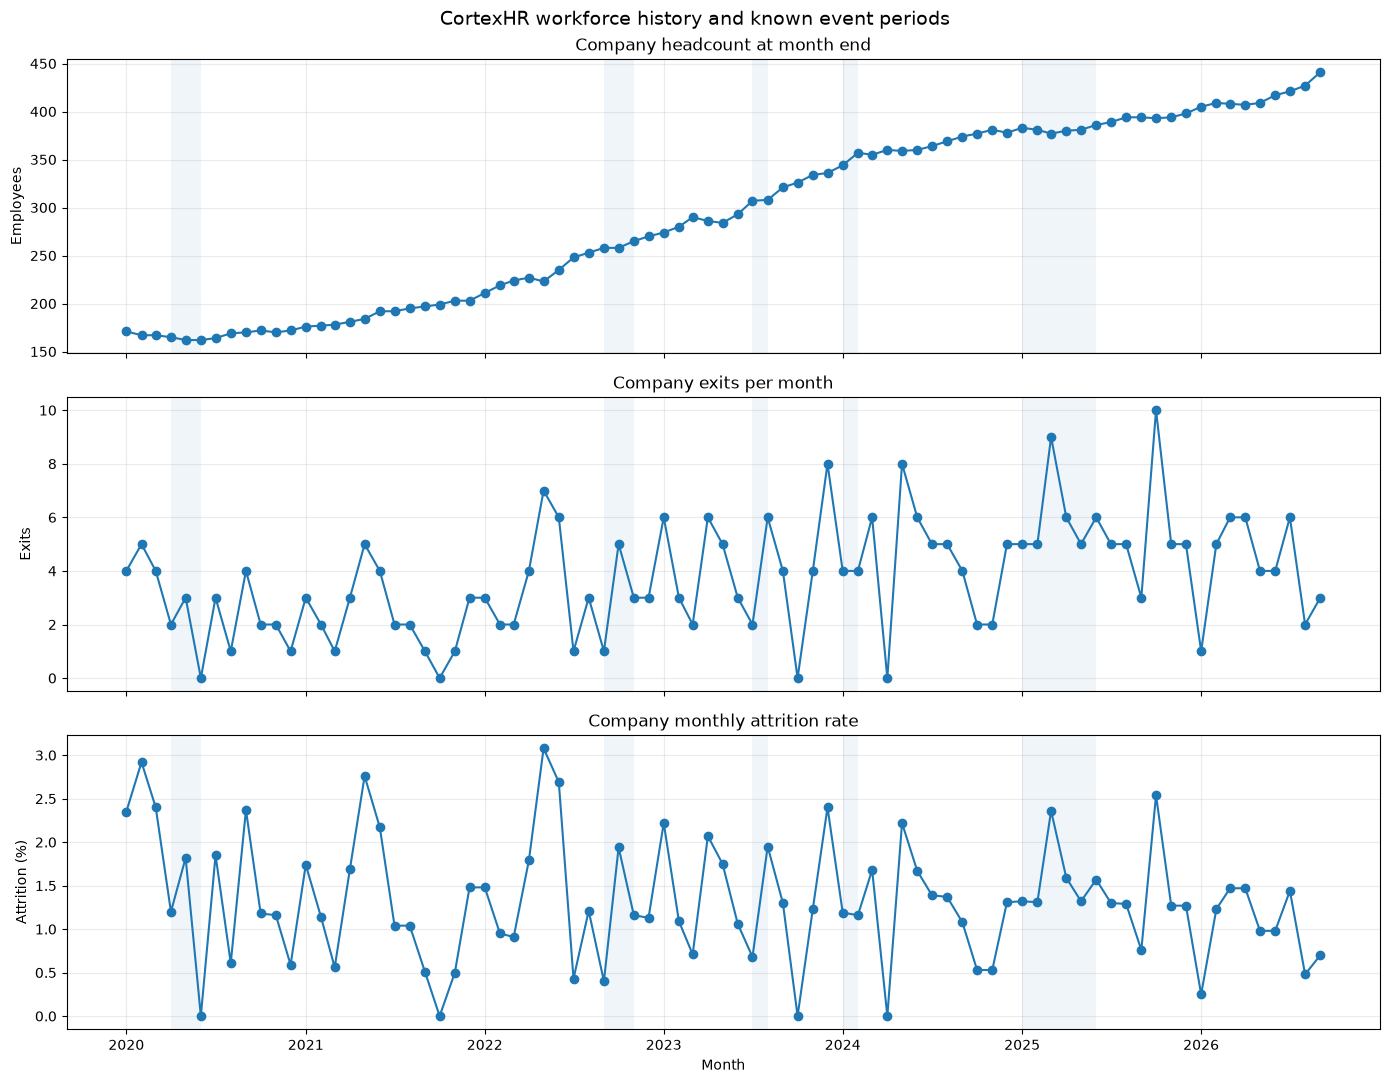

,headcount_end,exits,attrition_rate_monthly_pct
calendar_month,,,
1,280.571429,3.714286,1.507143
2,284.285714,3.714286,1.400000
3,285.571429,4.285714,1.441429
4,286.571429,3.857143,1.401429
5,286.000000,5.285714,1.990000
6,292.142857,4.142857,1.448571
7,297.857143,3.428571,1.161429
8,302.142857,3.428571,1.135714
9,307.857143,2.857143,1.017143


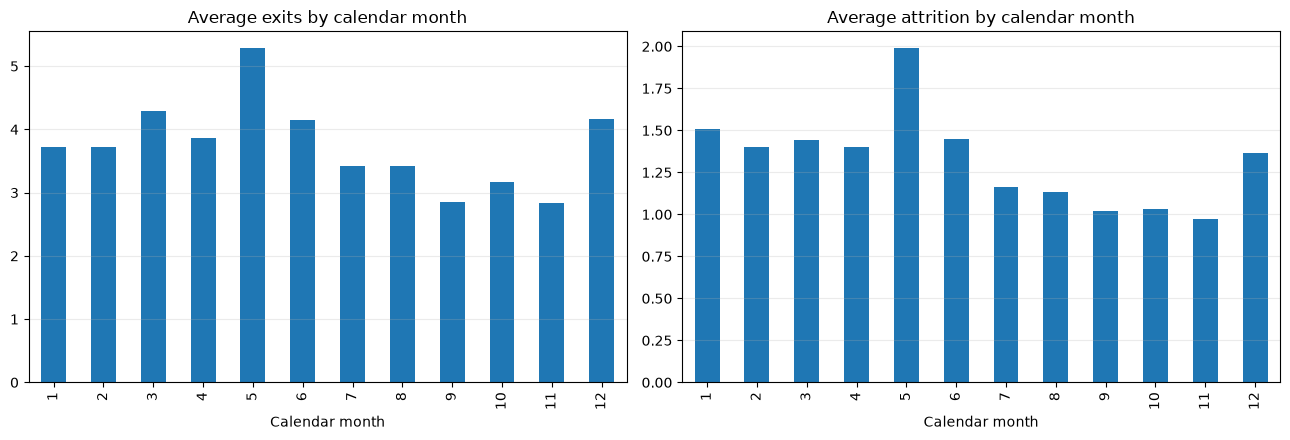

Potential unusual months for review (statistical flags, not data errors):


,headcount_end,hires,exits,headcount_change,exit_zscore
month,,,,,
2022-06-01,235,18,6,12.0,1.070181
2022-07-01,248,14,1,13.0,-1.311266
2023-03-01,290,12,2,10.0,-0.834976
2023-06-01,293,12,3,9.0,-0.358687
2023-07-01,307,16,2,14.0,-0.834976
2023-09-01,321,17,4,13.0,0.117602
2023-12-01,336,10,8,2.0,2.022760
2024-02-01,357,17,4,13.0,0.117602
2024-05-01,359,7,8,-1.0,2.022760


In [3]:
company = history[history.department_id == "ALL"].sort_values("month").set_index("month")

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for ax, col, title, ylabel in [
    (axes[0], "headcount_end", "Company headcount at month end", "Employees"),
    (axes[1], "exits", "Company exits per month", "Exits"),
    (axes[2], "attrition_rate_monthly_pct", "Company monthly attrition rate", "Attrition (%)")
]:
    ax.plot(company.index, company[col], marker="o", linewidth=1.5)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    for _, ev in events.iterrows():
        ax.axvspan(ev.start_date, ev.end_date, alpha=0.07)
axes[-1].set_xlabel("Month")
fig.suptitle("CortexHR workforce history and known event periods", fontsize=14)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task16_historical_trends.png", dpi=160, bbox_inches="tight")
plt.show()

seasonal_profile = (
    company.assign(calendar_month=company.index.month)
    .groupby("calendar_month")[["headcount_end", "exits", "attrition_rate_monthly_pct"]].mean()
)
display(seasonal_profile)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
seasonal_profile["exits"].plot(kind="bar", ax=axes[0], title="Average exits by calendar month")
seasonal_profile["attrition_rate_monthly_pct"].plot(kind="bar", ax=axes[1], title="Average attrition by calendar month")
for ax in axes:
    ax.set_xlabel("Calendar month")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task16_seasonality_profile.png", dpi=160, bbox_inches="tight")
plt.show()

company_changes = company[["headcount_end", "hires", "exits"]].copy()
company_changes["headcount_change"] = company_changes["headcount_end"].diff()
company_changes["exit_zscore"] = (
    (company_changes["exits"] - company_changes["exits"].mean())
    / company_changes["exits"].std(ddof=0)
)
unusual_months = company_changes[
    (company_changes["exit_zscore"].abs() >= 2)
    | (company_changes["headcount_change"].abs() >= 2 * company_changes["headcount_change"].std(ddof=0))
]
print("Potential unusual months for review (statistical flags, not data errors):")
display(unusual_months)

## 4. Event features, baseline and SARIMAX model

In [4]:
EVENT_FEATURES = [
    "event_active", "hiring_freeze_event", "hiring_drive_event",
    "policy_event", "compensation_event"
]
CALENDAR_FEATURES = [
    "hiring_drive_flag", "appraisal_cycle_flag", "financial_year_end_flag"
]
MODEL_VERSION = "cortexhr-forecast-sarimax-events-v1.0"
Z80 = float(norm.ppf(0.90))  # central 80% prediction interval

def build_event_features(department_id, dates, base_frame=None, future=False):
    dates = pd.DatetimeIndex(dates)
    records = []
    for date in dates:
        if future:
            relevant = events.iloc[0:0]
        else:
            active = (events.start_date <= date) & (events.end_date >= date)
            if department_id == "ALL":
                relevant = events.loc[active]  # all known events affect the company aggregate
            else:
                relevant = events.loc[
                    active & ((events.department_id == "ALL") | (events.department_id == department_id))
                ]
        names = " ".join(relevant.event_name.astype(str).str.lower().tolist())
        records.append({
            "event_active": int(len(relevant) > 0),
            "hiring_freeze_event": int("hiring freeze" in names),
            "hiring_drive_event": int(any(x in names for x in ["hiring drive", "scale-up", "build-out"])),
            "policy_event": int("policy" in names),
            "compensation_event": int(any(x in names for x in ["increment", "appraisal", "bonus"]))
        })
    result = pd.DataFrame(records, index=dates)
    if future:
        # No future events were supplied. Known recurring calendar flags are retained.
        result["hiring_drive_flag"] = 0
        result["appraisal_cycle_flag"] = (dates.month == 4).astype(int)
        result["financial_year_end_flag"] = (dates.month == 3).astype(int)
    else:
        if base_frame is None:
            raise ValueError("base_frame is required for historical event features")
        result["hiring_drive_flag"] = base_frame.loc[dates, "hiring_drive_flag"].astype(int).values
        result["appraisal_cycle_flag"] = base_frame.loc[dates, "appraisal_cycle_flag"].astype(int).values
        result["financial_year_end_flag"] = base_frame.loc[dates, "financial_year_end_flag"].astype(int).values
    return result[EVENT_FEATURES + CALENDAR_FEATURES].astype(float)

def get_series(department_id, target):
    frame = (
        history[history.department_id == department_id]
        .sort_values("month").set_index("month").asfreq("MS")
    )
    y = frame[target].astype(float)
    X = build_event_features(department_id, frame.index, base_frame=frame)
    return y, X

def baseline_forecast(y, future_dates, lookback=36):
    # Linear trend on latest 36 months + half-strength month-of-year seasonal residual.
    y = y.astype(float).dropna()
    train = y.iloc[-min(lookback, len(y)):]
    if len(train) < 18:
        raise ValueError("At least 18 months are required for the seasonal baseline.")
    t = np.arange(len(train), dtype=float)
    slope, intercept = np.polyfit(t, train.values, 1)
    residuals = train.values - (intercept + slope * t)
    residual_table = pd.DataFrame({"month": train.index.month, "residual": residuals})
    seasonal = residual_table.groupby("month").residual.mean()
    future_t = np.arange(len(train), len(train) + len(future_dates), dtype=float)
    trend = intercept + slope * future_t
    adjustment = np.array([seasonal.get(d.month, 0.0) for d in future_dates])
    point = trend + 0.5 * adjustment
    sigma = float(np.std(residuals, ddof=1)) if len(residuals) > 1 else 0.0
    return (
        pd.Series(point, index=future_dates),
        pd.Series(point - Z80 * sigma, index=future_dates),
        pd.Series(point + Z80 * sigma, index=future_dates)
    )

def sarimax_forecast(y, X, future_dates, X_future):
    varying = [c for c in X.columns if X[c].nunique(dropna=False) > 1]
    X_fit = X[varying] if varying else None
    X_next = X_future[varying] if varying else None
    model = SARIMAX(
        y.astype(float), exog=X_fit,
        order=(0, 1, 1), seasonal_order=(0, 1, 1, 12),
        trend="n", enforce_stationarity=False, enforce_invertibility=False
    )
    fitted = model.fit(disp=False, maxiter=500)
    pred = fitted.get_forecast(steps=len(future_dates), exog=X_next)
    mean = pd.Series(np.asarray(pred.predicted_mean, dtype=float), index=future_dates)
    ci = pred.conf_int(alpha=0.20)
    lower = pd.Series(ci.iloc[:, 0].to_numpy(dtype=float), index=future_dates)
    upper = pd.Series(ci.iloc[:, 1].to_numpy(dtype=float), index=future_dates)
    resid_sigma = float(np.nanstd(fitted.resid, ddof=1))
    lower = lower.where(np.isfinite(lower), mean - Z80 * resid_sigma)
    upper = upper.where(np.isfinite(upper), mean + Z80 * resid_sigma)
    lower = pd.Series(np.minimum(lower.values, mean.values), index=future_dates)
    upper = pd.Series(np.maximum(upper.values, mean.values), index=future_dates)
    return mean, lower, upper, fitted

def forecast_one_series(department_id, target, train_end, future_dates):
    y, X = get_series(department_id, target)
    mask = y.index <= train_end
    y_train, X_train = y.loc[mask], X.loc[mask]
    if len(y_train) < 30:
        raise ValueError(f"Not enough training data for {department_id}/{target}")
    X_future = build_event_features(department_id, future_dates, future=True)
    base_mean, base_lower, base_upper = baseline_forecast(y_train, future_dates)
    try:
        model_mean, model_lower, model_upper, fitted = sarimax_forecast(
            y_train, X_train, future_dates, X_future
        )
        model_name = "SARIMAX(0,1,1)x(0,1,1,12) + workforce-event regressors"
        converged = bool(fitted.mle_retvals.get("converged", True))
    except Exception as exc:
        # Explicit fallback; the report records the fallback method.
        model_mean, model_lower, model_upper = base_mean.copy(), base_lower.copy(), base_upper.copy()
        model_name = f"Seasonal baseline fallback ({type(exc).__name__})"
        converged = False
    if target in ["headcount_end", "exits", "attrition_rate_monthly_pct"]:
        base_mean, base_lower = base_mean.clip(lower=0), base_lower.clip(lower=0)
        model_mean, model_lower = model_mean.clip(lower=0), model_lower.clip(lower=0)
    return {
        "actual": y, "baseline_mean": base_mean, "baseline_lower": base_lower,
        "baseline_upper": base_upper, "model_mean": model_mean,
        "model_lower": model_lower, "model_upper": model_upper,
        "model_name": model_name, "converged": converged
    }

print("Methods ready: seasonal baseline and event-aware seasonal SARIMAX.")

Methods ready: seasonal baseline and event-aware seasonal SARIMAX.


## 5. Six-month holdout backtest

In [5]:
backtest_dates = pd.DatetimeIndex(history.month.drop_duplicates().sort_values().iloc[-6:])
backtest_train_end = backtest_dates[0] - pd.offsets.MonthBegin(1)
print("Train through:", backtest_train_end.date())
print("Holdout:", [d.strftime("%Y-%m") for d in backtest_dates])

backtest_rows = []
backtest_cache = {}

# Forecast every department (including D00) for headcount and exits.
for target in ["headcount_end", "exits"]:
    for dept in department_ids:
        result = forecast_one_series(dept, target, backtest_train_end, backtest_dates)
        backtest_cache[(target, dept)] = result
        actual = result["actual"].reindex(backtest_dates)
        for date in backtest_dates:
            backtest_rows.append({
                "metric": target, "department_id": dept, "forecast_month": date,
                "actual": float(actual.loc[date]),
                "baseline_forecast": float(result["baseline_mean"].loc[date]),
                "model_forecast": float(result["model_mean"].loc[date]),
                "model_name": result["model_name"], "model_converged": result["converged"]
            })

    # Company totals are sums of department series, not an additional series.
    actual_all = (
        history[history.department_id != "ALL"]
        .pivot(index="month", columns="department_id", values=target)
        .sum(axis=1).reindex(backtest_dates)
    )
    base_all = sum(backtest_cache[(target, dept)]["baseline_mean"] for dept in department_ids)
    model_all = sum(backtest_cache[(target, dept)]["model_mean"] for dept in department_ids)
    for date in backtest_dates:
        backtest_rows.append({
            "metric": target, "department_id": "ALL", "forecast_month": date,
            "actual": float(actual_all.loc[date]),
            "baseline_forecast": float(base_all.loc[date]),
            "model_forecast": float(model_all.loc[date]),
            "model_name": "Department forecasts summed to company total",
            "model_converged": all(backtest_cache[(target, d)]["converged"] for d in department_ids)
        })

# Attrition-rate forecast is a company-wide series in the supplied sample.
attrition_backtest = forecast_one_series(
    "ALL", "attrition_rate_monthly_pct", backtest_train_end, backtest_dates
)
backtest_cache[("attrition_rate_monthly_pct", "ALL")] = attrition_backtest
for date in backtest_dates:
    backtest_rows.append({
        "metric": "attrition_rate_monthly_pct", "department_id": "ALL",
        "forecast_month": date,
        "actual": float(attrition_backtest["actual"].loc[date]),
        "baseline_forecast": float(attrition_backtest["baseline_mean"].loc[date]),
        "model_forecast": float(attrition_backtest["model_mean"].loc[date]),
        "model_name": attrition_backtest["model_name"],
        "model_converged": attrition_backtest["converged"]
    })

backtest_predictions = pd.DataFrame(backtest_rows)
print("Backtest rows:", len(backtest_predictions))
display(backtest_predictions.head(12))

Train through: 2026-03-01
Holdout: ['2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']
Backtest rows: 150


,metric,department_id,forecast_month,actual,baseline_forecast,model_forecast,model_name,model_converged
0,headcount_end,D00,2026-04-01,1.0,1.000000,0.999929,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
1,headcount_end,D00,2026-05-01,1.0,1.000000,1.000000,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
2,headcount_end,D00,2026-06-01,1.0,1.000000,1.000000,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
3,headcount_end,D00,2026-07-01,1.0,1.000000,1.000000,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
4,headcount_end,D00,2026-08-01,1.0,1.000000,1.000000,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
5,headcount_end,D00,2026-09-01,1.0,1.000000,1.000000,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",False
6,headcount_end,D01,2026-04-01,155.0,159.675032,156.064565,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",True
7,headcount_end,D01,2026-05-01,155.0,160.245817,155.080638,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",True
8,headcount_end,D01,2026-06-01,158.0,162.649936,157.747304,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",True
9,headcount_end,D01,2026-07-01,156.0,165.720721,161.600010,"SARIMAX(0,1,1)x(0,1,1,12) + workforce-event re...",True


## 6. Backtest metrics and comparison

In [6]:
def metrics_for(frame, prediction_column):
    actual = frame.actual.to_numpy(dtype=float)
    predicted = frame[prediction_column].to_numpy(dtype=float)
    error = predicted - actual
    denom = np.abs(actual).sum()
    return {
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "WAPE_pct": float(np.abs(error).sum() / denom * 100) if denom else np.nan
    }

metric_rows = []
for metric_name, group in backtest_predictions.groupby("metric"):
    for model_name, column in [
        ("Seasonal baseline", "baseline_forecast"),
        ("SARIMAX candidate", "model_forecast")
    ]:
        metric_rows.append({
            "metric": metric_name, "model": model_name,
            **metrics_for(group, column)
        })
backtest_metrics = pd.DataFrame(metric_rows)
display(backtest_metrics)

series_rows = []
for (metric_name, dept), group in backtest_predictions.groupby(["metric", "department_id"]):
    for model_name, column in [
        ("Seasonal baseline", "baseline_forecast"),
        ("SARIMAX candidate", "model_forecast")
    ]:
        series_rows.append({
            "metric": metric_name, "department_id": dept, "model": model_name,
            **metrics_for(group, column)
        })
series_backtest_metrics = pd.DataFrame(series_rows)

comparison = backtest_metrics.pivot(index="metric", columns="model", values="WAPE_pct")
comparison["lower_WAPE_model"] = np.where(
    comparison["SARIMAX candidate"] < comparison["Seasonal baseline"],
    "SARIMAX candidate", "Seasonal baseline"
)
selected_model_by_metric = comparison["lower_WAPE_model"].to_dict()
print("Model selected by six-month holdout WAPE for each metric:")
display(comparison)
print("Final model selection:", selected_model_by_metric)

,metric,model,MAE,RMSE,WAPE_pct
0,attrition_rate_monthly_pct,Seasonal baseline,0.451321,0.502237,44.759111
1,attrition_rate_monthly_pct,SARIMAX candidate,0.477035,0.540923,47.309254
2,exits,Seasonal baseline,0.565864,0.859803,81.484427
3,exits,SARIMAX candidate,0.597250,0.911732,86.003971
4,headcount_end,Seasonal baseline,3.266341,4.223536,4.662502
5,headcount_end,SARIMAX candidate,1.447458,2.282337,2.066157


Model selected by six-month holdout WAPE for each metric:


model,SARIMAX candidate,Seasonal baseline,lower_WAPE_model
metric,,,
attrition_rate_monthly_pct,47.309254,44.759111,Seasonal baseline
exits,86.003971,81.484427,Seasonal baseline
headcount_end,2.066157,4.662502,SARIMAX candidate


Final model selection: {'attrition_rate_monthly_pct': 'Seasonal baseline', 'exits': 'Seasonal baseline', 'headcount_end': 'SARIMAX candidate'}


## 7. Refit on all history and create forecasts

In [7]:
future_dates = forecast_months
final_cache = {}

for target in ["headcount_end", "exits"]:
    for dept in department_ids:
        final_cache[(target, dept)] = forecast_one_series(
            dept, target, trained_through, future_dates
        )

def selected_series_values(result, target):
    # Select the method with lower WAPE on the six-month holdout.
    if selected_model_by_metric[target] == "SARIMAX candidate":
        return result["model_mean"], result["model_lower"], result["model_upper"]
    return result["baseline_mean"], result["baseline_lower"], result["baseline_upper"]

def aggregate_mean(target):
    return sum(
        selected_series_values(final_cache[(target, dept)], target)[0]
        for dept in department_ids
    )

def aggregate_bounds(target, side):
    # Combine department prediction variances assuming independent forecast errors.
    se_list = []
    for dept in department_ids:
        _, lower, upper = selected_series_values(final_cache[(target, dept)], target)
        se_list.append((upper - lower) / (2 * Z80))
    total_se = np.sqrt(sum(se ** 2 for se in se_list))
    mean = aggregate_mean(target)
    if side == "lower":
        return (mean - Z80 * total_se).clip(lower=0)
    return (mean + Z80 * total_se).clip(lower=0)

final_cache[("attrition_rate_monthly_pct", "ALL")] = forecast_one_series(
    "ALL", "attrition_rate_monthly_pct", trained_through, future_dates
)

forecast_lookup = {}
for target in ["headcount_end", "exits"]:
    for dept in department_ids:
        result = final_cache[(target, dept)]
        selected_mean, selected_lower, selected_upper = selected_series_values(result, target)
        selected_method = (
            result["model_name"]
            if selected_model_by_metric[target] == "SARIMAX candidate"
            else "36-month linear trend + half-strength seasonality (selected by holdout WAPE)"
        )
        for date in future_dates:
            forecast_lookup[(target, dept, date)] = (
                selected_mean.loc[date],
                selected_lower.loc[date],
                selected_upper.loc[date],
                selected_method
            )
    all_mean = aggregate_mean(target)
    all_lower = aggregate_bounds(target, "lower")
    all_upper = aggregate_bounds(target, "upper")
    for date in future_dates:
        forecast_lookup[(target, "ALL", date)] = (
            all_mean.loc[date], all_lower.loc[date], all_upper.loc[date],
            "Department forecasts summed to company total"
        )

attrition_final = final_cache[("attrition_rate_monthly_pct", "ALL")]
attrition_selected_mean, attrition_selected_lower, attrition_selected_upper = selected_series_values(
    attrition_final, "attrition_rate_monthly_pct"
)
attrition_selected_method = (
    attrition_final["model_name"]
    if selected_model_by_metric["attrition_rate_monthly_pct"] == "SARIMAX candidate"
    else "36-month linear trend + half-strength seasonality (selected by holdout WAPE)"
)
for date in future_dates:
    forecast_lookup[("attrition_rate_monthly_pct", "ALL", date)] = (
        attrition_selected_mean.loc[date],
        attrition_selected_lower.loc[date],
        attrition_selected_upper.loc[date],
        attrition_selected_method
    )

# Main file: exact row/column structure from sample_forecast.csv.
forecast_output = sample_template.copy()
forecast_output["trained_through"] = trained_through.strftime("%Y-%m")
forecast_output["model_version"] = MODEL_VERSION

for idx, row in forecast_output.iterrows():
    key = (row.metric, row.department_id, row.forecast_month)
    if key not in forecast_lookup:
        raise KeyError(f"No forecast for sample row: {key}")
    mean, lower, upper, method = forecast_lookup[key]
    forecast_output.loc[idx, "forecast_value"] = max(0.0, float(mean))
    forecast_output.loc[idx, "lower_80"] = max(0.0, float(lower))
    forecast_output.loc[idx, "upper_80"] = max(float(mean), float(upper))
    forecast_output.loc[idx, "method"] = method

forecast_output["forecast_month"] = forecast_output["forecast_month"].dt.strftime("%Y-%m-%d")
forecast_output = forecast_output[list(sample_template.columns)]
for col in ["forecast_value", "lower_80", "upper_80"]:
    forecast_output[col] = forecast_output[col].astype(float).round(1)

# Supplementary exits file: company total plus all departments, including D00.
exit_rows = []
counter = 1
for dept in ["ALL"] + department_ids:
    for date in future_dates:
        mean, lower, upper, method = forecast_lookup[("exits", dept, date)]
        exit_rows.append({
            "forecast_id": f"EX-{counter:04d}", "metric": "exits",
            "department_id": dept, "forecast_month": date.strftime("%Y-%m-%d"),
            "forecast_value": round(max(0.0, float(mean)), 1),
            "lower_80": round(max(0.0, float(lower)), 1),
            "upper_80": round(max(float(mean), float(upper)), 1),
            "method": method, "trained_through": trained_through.strftime("%Y-%m"),
            "model_version": MODEL_VERSION
        })
        counter += 1
exits_forecast_output = pd.DataFrame(exit_rows)

print("Sample-compatible forecast:", forecast_output.shape)
print("Expected sample shape:", sample_template.shape)
print("Columns match:", list(forecast_output.columns) == list(sample_template.columns))
display(forecast_output.head(12))
display(exits_forecast_output.head(12))

Sample-compatible forecast: (72, 10)
Expected sample shape: (72, 10)
Columns match: True


,forecast_id,metric,department_id,forecast_month,forecast_value,lower_80,upper_80,method,trained_through,model_version
0,FC-0067,attrition_rate_monthly_pct,ALL,2026-10-01,1.0,0.3,1.8,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
1,FC-0068,attrition_rate_monthly_pct,ALL,2026-11-01,1.0,0.3,1.8,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
2,FC-0069,attrition_rate_monthly_pct,ALL,2026-12-01,1.4,0.6,2.1,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
3,FC-0070,attrition_rate_monthly_pct,ALL,2027-01-01,1.0,0.2,1.7,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
4,FC-0071,attrition_rate_monthly_pct,ALL,2027-02-01,1.1,0.4,1.9,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
5,FC-0072,attrition_rate_monthly_pct,ALL,2027-03-01,1.4,0.7,2.2,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
6,FC-0001,headcount_end,ALL,2026-10-01,442.7,437.8,447.5,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
7,FC-0002,headcount_end,ALL,2026-11-01,446.1,439.0,453.3,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
8,FC-0003,headcount_end,ALL,2026-12-01,447.3,438.5,456.1,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
9,FC-0004,headcount_end,ALL,2027-01-01,453.1,442.8,463.3,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0


,forecast_id,metric,department_id,forecast_month,forecast_value,lower_80,upper_80,method,trained_through,model_version
0,EX-0001,exits,ALL,2026-10-01,4.8,2.6,7.0,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
1,EX-0002,exits,ALL,2026-11-01,4.6,2.5,6.8,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
2,EX-0003,exits,ALL,2026-12-01,5.6,3.3,7.8,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
3,EX-0004,exits,ALL,2027-01-01,4.3,2.2,6.5,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
4,EX-0005,exits,ALL,2027-02-01,5.0,2.8,7.3,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
5,EX-0006,exits,ALL,2027-03-01,6.4,4.1,8.6,Department forecasts summed to company total,2026-09,cortexhr-forecast-sarimax-events-v1.0
6,EX-0007,exits,D00,2026-10-01,0.0,0.0,0.0,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
7,EX-0008,exits,D00,2026-11-01,0.0,0.0,0.0,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
8,EX-0009,exits,D00,2026-12-01,0.0,0.0,0.0,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0
9,EX-0010,exits,D00,2027-01-01,0.0,0.0,0.0,36-month linear trend + half-strength seasonal...,2026-09,cortexhr-forecast-sarimax-events-v1.0


## 8. Forecast charts

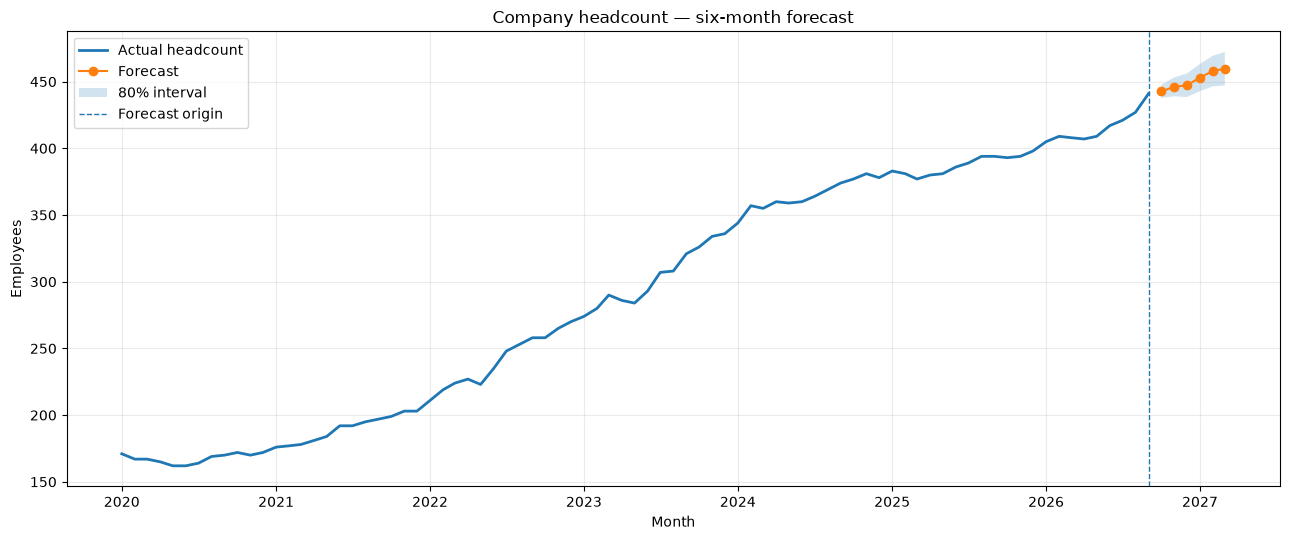

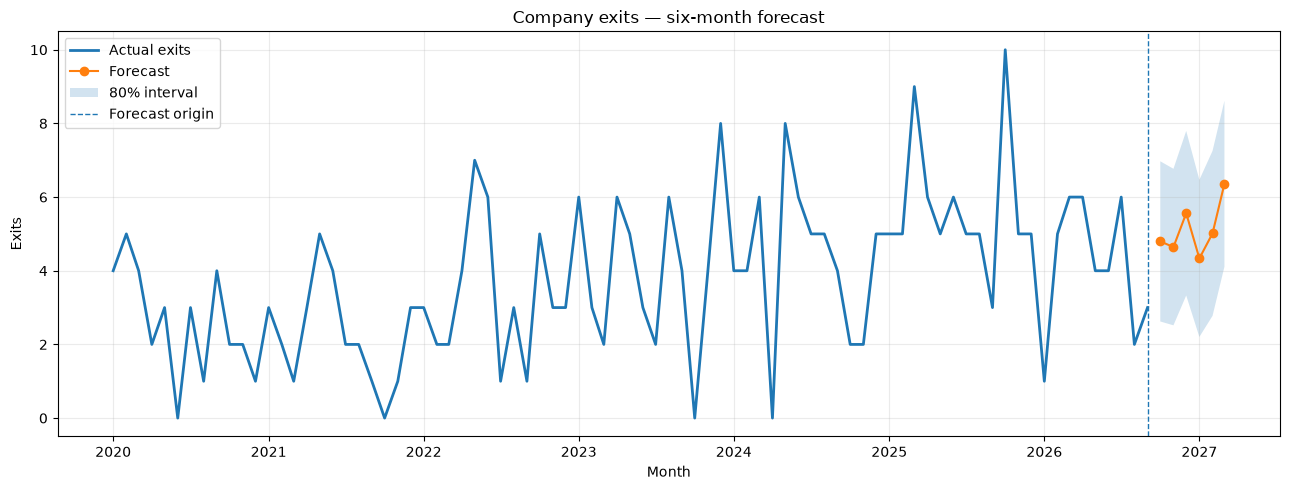

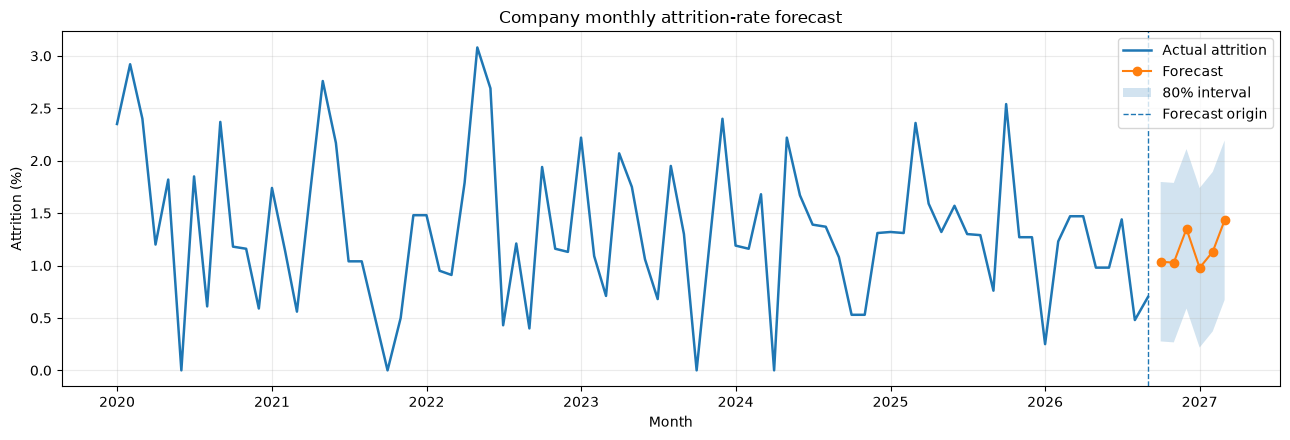

In [8]:
company_actual = (
    history[history.department_id == "ALL"].set_index("month")["headcount_end"].sort_index()
)
headcount_mean = aggregate_mean("headcount_end")
headcount_lower = aggregate_bounds("headcount_end", "lower")
headcount_upper = aggregate_bounds("headcount_end", "upper")

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(company_actual.index, company_actual.values, label="Actual headcount", linewidth=2)
ax.plot(future_dates, headcount_mean.values, marker="o", label="Forecast")
ax.fill_between(future_dates, headcount_lower.values, headcount_upper.values, alpha=0.2, label="80% interval")
ax.axvline(trained_through, linestyle="--", linewidth=1, label="Forecast origin")
ax.set(title="Company headcount — six-month forecast", xlabel="Month", ylabel="Employees")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task16_headcount_forecast.png", dpi=160, bbox_inches="tight")
plt.show()

exits_actual = (
    history[history.department_id == "ALL"].set_index("month")["exits"].sort_index()
)
exits_mean = aggregate_mean("exits")
exits_lower = aggregate_bounds("exits", "lower")
exits_upper = aggregate_bounds("exits", "upper")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(exits_actual.index, exits_actual.values, label="Actual exits", linewidth=2)
ax.plot(future_dates, exits_mean.values, marker="o", label="Forecast")
ax.fill_between(future_dates, exits_lower.values, exits_upper.values, alpha=0.2, label="80% interval")
ax.axvline(trained_through, linestyle="--", linewidth=1, label="Forecast origin")
ax.set(title="Company exits — six-month forecast", xlabel="Month", ylabel="Exits")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task16_exits_forecast.png", dpi=160, bbox_inches="tight")
plt.show()

attrition_actual = (
    history[history.department_id == "ALL"].set_index("month")["attrition_rate_monthly_pct"].sort_index()
)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(attrition_actual.index, attrition_actual.values, label="Actual attrition", linewidth=1.8)
ax.plot(future_dates, attrition_selected_mean.values, marker="o", label="Forecast")
ax.fill_between(
    future_dates, attrition_selected_lower.values,
    attrition_selected_upper.values, alpha=0.2, label="80% interval"
)
ax.axvline(trained_through, linestyle="--", linewidth=1, label="Forecast origin")
ax.set(title="Company monthly attrition-rate forecast", xlabel="Month", ylabel="Attrition (%)")
ax.grid(alpha=0.25); ax.legend(); fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task16_attrition_forecast.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Save reports, evidence and model metadata

In [9]:
forecast_path = REPORT_DIR / "task16_forecast.csv"
exits_path = REPORT_DIR / "task16_exits_forecast.csv"
backtest_path = REPORT_DIR / "task16_backtest_predictions.csv"
metrics_path = REPORT_DIR / "task16_backtest_metrics.csv"
series_metrics_path = REPORT_DIR / "task16_backtest_series_metrics.csv"
events_review_path = REPORT_DIR / "task16_workforce_events_review.csv"

forecast_output.to_csv(forecast_path, index=False)
exits_forecast_output.to_csv(exits_path, index=False)
backtest_predictions.to_csv(backtest_path, index=False)
backtest_metrics.to_csv(metrics_path, index=False)
series_backtest_metrics.to_csv(series_metrics_path, index=False)
events.to_csv(events_review_path, index=False)

def dataframe_markdown_table(frame):
    display_frame = frame.copy()
    for column in display_frame.select_dtypes(include=["number"]).columns:
        display_frame[column] = display_frame[column].map(
            lambda value: "" if pd.isna(value) else f"{value:.3f}"
        )
    headers = [str(column) for column in display_frame.columns]
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]
    for row in display_frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    return "\\n".join(lines)

report_lines = [
    "# Task 16 — Workforce Forecast Report", "",
    "## Scope",
    f"- Historical period: {history.month.min():%Y-%m} to {trained_through:%Y-%m}.",
    f"- Forecast period: {future_dates.min():%Y-%m} to {future_dates.max():%Y-%m}.",
    f"- Historical records: {len(history)} across {history.department_id.nunique()} series (company total and departments).",
    f"- Workforce events reviewed: {len(events)}.",
    "- Main forecast follows the exact rows and columns in the supplied sample_forecast.csv.",
    "- Exits are supplied as a supplementary forecast because the sample template contains headcount and company attrition rows but no exits rows.",
    "",
    "## Methods",
    "- Baseline: linear trend fitted on the latest 36 months plus half-strength month-of-year seasonal residual.",
    "- Candidate: SARIMAX(0,1,1) x (0,1,1,12) with workforce-event and calendar regressors.",
    "- Department event features include company-wide events and that department's own events. The ALL series includes all supplied events.",
    "- No future workforce events were supplied. Future event indicators are therefore zero; March financial-year-end and April appraisal calendar flags are retained.",
    "- Company headcount and exits forecasts are summed from department forecasts, including D00.",
    "- Central 80% prediction intervals are reported. Aggregate department forecast variances are combined assuming independent errors.",
    "",
    "## Six-month holdout backtest",
    f"- Training data ends: {backtest_train_end:%Y-%m}.",
    f"- Holdout months: {', '.join(d.strftime('%Y-%m') for d in backtest_dates)}.",
    "- Metrics: MAE, RMSE and WAPE (lower is better).",
    "- Final forecast method is selected per metric using the lower aggregate holdout WAPE; the candidate is not assumed to win every metric.", "",
    dataframe_markdown_table(backtest_metrics), "",
    "### Selected method by metric",
    dataframe_markdown_table(pd.DataFrame([{"metric": k, "selected_method": v} for k, v in selected_model_by_metric.items()])), "",
    "## Data quality and limitations",
    f"- Missing values: history={int(history.isna().sum().sum())}; events={int(events.isna().sum().sum())}; sample={int(sample_template.isna().sum().sum())}.",
    f"- Headcount movement equation mismatches: {int((history.headcount_reconciliation_difference != 0).sum())} rows.",
    "- Workforce-event associations are descriptive model inputs, not proof of causal effects.",
    "- Future hiring freezes, hiring drives and other events cannot be anticipated unless future event information is provided.",
    "- Backtesting uses one six-month holdout origin; performance may differ in other periods.",
    "- Small departments and sparse exits series may have relatively wide uncertainty.",
    "- Forecasts support workforce planning and human review; they are not guaranteed outcomes.",
    "",
    "## Deliverables",
    "- task16_forecast.csv — sample-compatible headcount and company attrition forecast.",
    "- task16_exits_forecast.csv — supplementary exits forecast by department and company.",
    "- task16_backtest_predictions.csv and task16_backtest_metrics.csv — holdout predictions and metrics.",
    "- task16_backtest_series_metrics.csv — per-series metrics.",
    "- task16_workforce_events_review.csv — supplied event register.",
    "- Evidence: task16_historical_trends.png, task16_seasonality_profile.png, task16_headcount_forecast.png, task16_exits_forecast.png, task16_attrition_forecast.png."
]
report_path = REPORT_DIR / "task16_workforce_forecast_report.md"
report_path.write_text("\\n".join(report_lines), encoding="utf-8")

metadata = {
    "task": 16,
    "title": "Workforce Headcount and Exits Forecast",
    "model_version": MODEL_VERSION,
    "trained_through": trained_through.strftime("%Y-%m"),
    "forecast_months": [d.strftime("%Y-%m") for d in future_dates],
    "history_start": history.month.min().strftime("%Y-%m"),
    "history_end": trained_through.strftime("%Y-%m"),
    "backtest_start": backtest_dates.min().strftime("%Y-%m"),
    "backtest_end": backtest_dates.max().strftime("%Y-%m"),
    "candidate_model": "SARIMAX(0,1,1)x(0,1,1,12) with workforce-event regressors",
    "selected_model_by_metric": selected_model_by_metric,
    "baseline": "36-month linear trend + half-strength seasonal residual",
    "prediction_interval": "central 80%",
    "statsmodels_version": statsmodels.__version__,
    "input_files": [HISTORY_PATH.name, EVENTS_PATH.name, SAMPLE_PATH.name]
}
metadata_path = MODEL_DIR / "task16_forecast_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved report:", report_path)
print("Saved metadata:", metadata_path)
for p in [forecast_path, exits_path, backtest_path, metrics_path, series_metrics_path, events_review_path]:
    print("Saved:", p)

Saved report: /workspace/phase-4/reports/task16_workforce_forecast_report.md
Saved metadata: /workspace/phase-4/models/task16_forecast_metadata.json
Saved: /workspace/phase-4/reports/task16_forecast.csv
Saved: /workspace/phase-4/reports/task16_exits_forecast.csv
Saved: /workspace/phase-4/reports/task16_backtest_predictions.csv
Saved: /workspace/phase-4/reports/task16_backtest_metrics.csv
Saved: /workspace/phase-4/reports/task16_backtest_series_metrics.csv
Saved: /workspace/phase-4/reports/task16_workforce_events_review.csv


## 10. Final validation checklist

In [11]:
# Diagnose the D00 forecast method mismatch

dept = "D00"
metric_name = "headcount_end"

expected = final_cache[(metric_name, dept)]["model_name"]

actual = saved_forecast.loc[
    (saved_forecast["metric"] == metric_name) &
    (saved_forecast["department_id"] == dept),
    "method"
].unique()

print("Expected method:", expected)
print("Saved CSV method:", actual)
print("Selected model:", selected_model_by_metric[metric_name])
print("SARIMAX converged:", final_cache[(metric_name, dept)]["converged"])

Expected method: SARIMAX(0,1,1)x(0,1,1,12) + workforce-event regressors
Saved CSV method: <StringArray>
[]
Length: 0, dtype: str
Selected model: SARIMAX candidate
SARIMAX converged: True


In [14]:

# ============================================================
# TASK 16 — COMPLETE FINAL VALIDATION
# ============================================================

# Reload generated files to validate the actual saved outputs.
saved_forecast = pd.read_csv(forecast_path)
saved_exits = pd.read_csv(exits_path)
saved_backtest = pd.read_csv(backtest_path)

# 1. Main forecast structure and data validation
assert len(saved_forecast) == len(sample_template)
assert list(saved_forecast.columns) == list(sample_template.columns)
assert saved_forecast.isna().sum().sum() == 0
assert (saved_forecast["lower_80"] <= saved_forecast["forecast_value"]).all()
assert (saved_forecast["forecast_value"] <= saved_forecast["upper_80"]).all()
assert saved_forecast["forecast_month"].nunique() == 6
assert set(saved_forecast["metric"].unique()) == set(sample_template["metric"].unique())

# 2. Supplementary exits forecast validation
assert len(saved_exits) == 6 * (len(department_ids) + 1)
assert saved_exits.isna().sum().sum() == 0
assert (saved_exits["lower_80"] <= saved_exits["forecast_value"]).all()
assert (saved_exits["forecast_value"] <= saved_exits["upper_80"]).all()

# 3. Backtest validation
assert saved_backtest["forecast_month"].nunique() == 6
assert saved_backtest[
    ["actual", "baseline_forecast", "model_forecast"]
].notna().all().all()

# 4. Validate headcount method for individual departments
headcount_departments = saved_forecast.loc[
    (saved_forecast["metric"] == "headcount_end") &
    (saved_forecast["department_id"] != "ALL"),
    "department_id"
].unique()

for dept in headcount_departments:
    expected = final_cache[("headcount_end", dept)]["model_name"]

    actual_labels = saved_forecast.loc[
        (saved_forecast["metric"] == "headcount_end") &
        (saved_forecast["department_id"] == dept),
        "method"
    ].unique()

    assert len(actual_labels) == 1 and actual_labels[0] == expected, (
        f"headcount_end/{dept}: forecast method mismatch"
    )

# 5. Validate company-level headcount aggregation
all_method = saved_forecast.loc[
    (saved_forecast["metric"] == "headcount_end") &
    (saved_forecast["department_id"] == "ALL"),
    "method"
].unique()

assert len(all_method) == 1
assert all_method[0] == "Department forecasts summed to company total"

# 6. Validate selected exits method
if selected_model_by_metric["exits"] == "Seasonal baseline":
    non_total_exits = saved_exits[
        saved_exits["department_id"] != "ALL"
    ]
    assert non_total_exits["method"].eq(baseline_label).all()

# 7. Final confirmation
print("PASS: main forecast row count and columns match sample_forecast.csv")
print("PASS: six forecast months and valid 80% interval ordering")
print("PASS: supplementary exits forecast created")
print("PASS: six-month holdout backtest contains no missing predictions")
print("PASS: headcount forecast methods match selected models")
print("PASS: company-level headcount aggregation validated")
print("PASS: exits forecasts use the selected seasonal baseline")
print("PASS: reports, metadata and evidence saved inside phase-4/")

print("\nSelected final models:", selected_model_by_metric)
print("\nTask 16 final validation completed.")


PASS: main forecast row count and columns match sample_forecast.csv
PASS: six forecast months and valid 80% interval ordering
PASS: supplementary exits forecast created
PASS: six-month holdout backtest contains no missing predictions
PASS: headcount forecast methods match selected models
PASS: company-level headcount aggregation validated
PASS: exits forecasts use the selected seasonal baseline
PASS: reports, metadata and evidence saved inside phase-4/

Selected final models: {'attrition_rate_monthly_pct': 'Seasonal baseline', 'exits': 'Seasonal baseline', 'headcount_end': 'SARIMAX candidate'}

Task 16 final validation completed.
